In [1]:
# Importación de bibliotecas necesarias
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Paso 1: Cargar los datos
data = pd.read_csv('C:/Users/srfue/Desktop/diagramas/csv/delitos_puerto_montt_2021.csv')

# Exploración inicial de los datos
print(data.head())
print(data.info())

  ANHO-MES  Homicidios  Hurtos  Lesiones leves  \
0   2005-1           0     249             100   
1   2005-2           0     253              91   
2   2005-3           2     242             107   
3   2005-4           4     306              95   
4   2005-5           0     268             107   

   Lesiones menos graves- graves o gravísimas  Otros robos con fuerza  \
0                                          44                      25   
1                                          37                       4   
2                                          31                       8   
3                                          30                      12   
4                                          29                      12   

   Robo con violencia o intimidación  Robo de objetos de o desde vehículo  \
0                                 44                                   34   
1                                 34                                   34   
2                            

In [5]:
# Paso 2: Preprocesamiento de datos
# Asegurarse de que la columna 'ANHO-MES' sea de tipo datetime
data['fecha'] = pd.to_datetime(data['ANHO-MES'], format='%Y-%m')

# Verificar la conversión
print(data['fecha'].head())

# Generar características temporales
data['mes'] = data['fecha'].dt.month
data['anio'] = data['fecha'].dt.year

# Seleccionar características relevantes para el modelo
features = ['anio', 'mes']
X = data[features]
y = data.drop(columns=features + ['fecha', 'ANHO-MES'])

# Convertir todos los valores de y a numéricos, reemplazando los no convertibles con NaN y luego eliminarlos
y = y.apply(pd.to_numeric, errors='coerce')

# Eliminar filas con NaN
y = y.dropna()

# Asegurarse de que X tenga las mismas filas que y después de eliminar NaNs
X = X.loc[y.index]

0   2005-01-01
1   2005-02-01
2   2005-03-01
3   2005-04-01
4   2005-05-01
Name: fecha, dtype: datetime64[ns]


In [7]:
# Paso 3: Separación de datos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [9]:
# Paso 4: Entrenamiento del modelo
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [11]:
# Paso 5: Evaluación del modelo
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print(f'Mean Squared Error: {mse}')

# Informe de los cinco delitos con mayor predicción
predicciones = pd.DataFrame(y_pred, columns=y.columns)
delitos_mayor_prediccion = predicciones.sum().sort_values(ascending=False).head(5)
print('Cinco delitos con mayor predicción:')
print(delitos_mayor_prediccion)

Mean Squared Error: 443.8214097142858
Cinco delitos con mayor predicción:
Hurtos                             13867.69
Consumo alcohol vía pública         9839.49
Daños                               7653.76
Violencia intrafamiliar a mujer     6948.00
Amenazas                            6358.96
dtype: float64


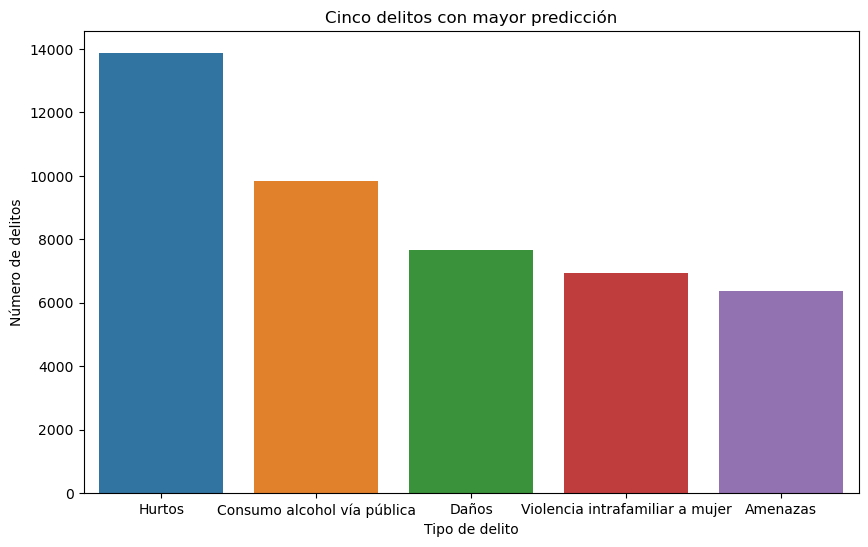

In [13]:
# Paso 6: Visualización de resultados
plt.figure(figsize=(10, 6))
sns.barplot(x=delitos_mayor_prediccion.index, y=delitos_mayor_prediccion.values)
plt.title('Cinco delitos con mayor predicción')
plt.ylabel('Número de delitos')
plt.xlabel('Tipo de delito')
plt.show()